# 04 — Grid search y random search

Las curvas del cuaderno anterior varían **un** hiperparámetro a la vez. Aquí se buscan varios a la vez con
**validación cruzada de 5 particiones** sobre el conjunto de desarrollo (la prueba sigue sin tocarse):

- **Grid search:** prueba *todas* las combinaciones de una malla.
- **Random search:** prueba un número fijo de combinaciones *sorteadas* de un espacio más amplio.

La regresión lineal (sin regularización) no tiene hiperparámetros que ajustar.

In [1]:
import sys
sys.path.append("../src")  # por si el paquete no está instalado con pip install -e .

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from proyecto_ml.data import SEMILLA, cargar_dataset, particionar
from proyecto_ml.metrics import resumen, rmse
from proyecto_ml.models import ARBOL, BOSQUE, KNN, LINEA_BASE, LINEAL, NOMBRES, construir_modelo

RESULTADOS = Path("..") / "resultados"
RESULTADOS.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 80)

import json
from scipy.stats import randint
from proyecto_ml.tuning import busqueda_grid, busqueda_random, mejores_hiperparametros, resultados_cv

In [2]:
datos = cargar_dataset()
X_dev, X_test, y_dev, y_test = particionar(datos)   # 80 % desarrollo, 20 % prueba (reservada)
print("desarrollo:", X_dev.shape, "| prueba:", X_test.shape)

desarrollo: (6972, 7) | prueba: (1744, 7)


## Árbol de decisión (grid search)

In [3]:
grilla_arbol = {"max_depth": [2, 3, 4, 5, 6, 8, 10, 12, 15, 20], "min_samples_leaf": [1, 5, 10, 20, 40]}
b_arbol, t_arbol = busqueda_grid(ARBOL, grilla_arbol, X_dev, y_dev)
print(f"{len(b_arbol.cv_results_['params'])} combinaciones en {t_arbol:.0f} s")
resultados_cv(b_arbol, k=5)

50 combinaciones en 8 s


,hiperparámetros,rmse_cv,desv_cv,ranking
0,"{'max_depth': 8, 'min_samples_leaf': 10}",1.258,0.015,1
1,"{'max_depth': 10, 'min_samples_leaf': 10}",1.266,0.014,2
2,"{'max_depth': 8, 'min_samples_leaf': 5}",1.272,0.017,3
3,"{'max_depth': 12, 'min_samples_leaf': 10}",1.273,0.015,4
4,"{'max_depth': 8, 'min_samples_leaf': 20}",1.273,0.017,5


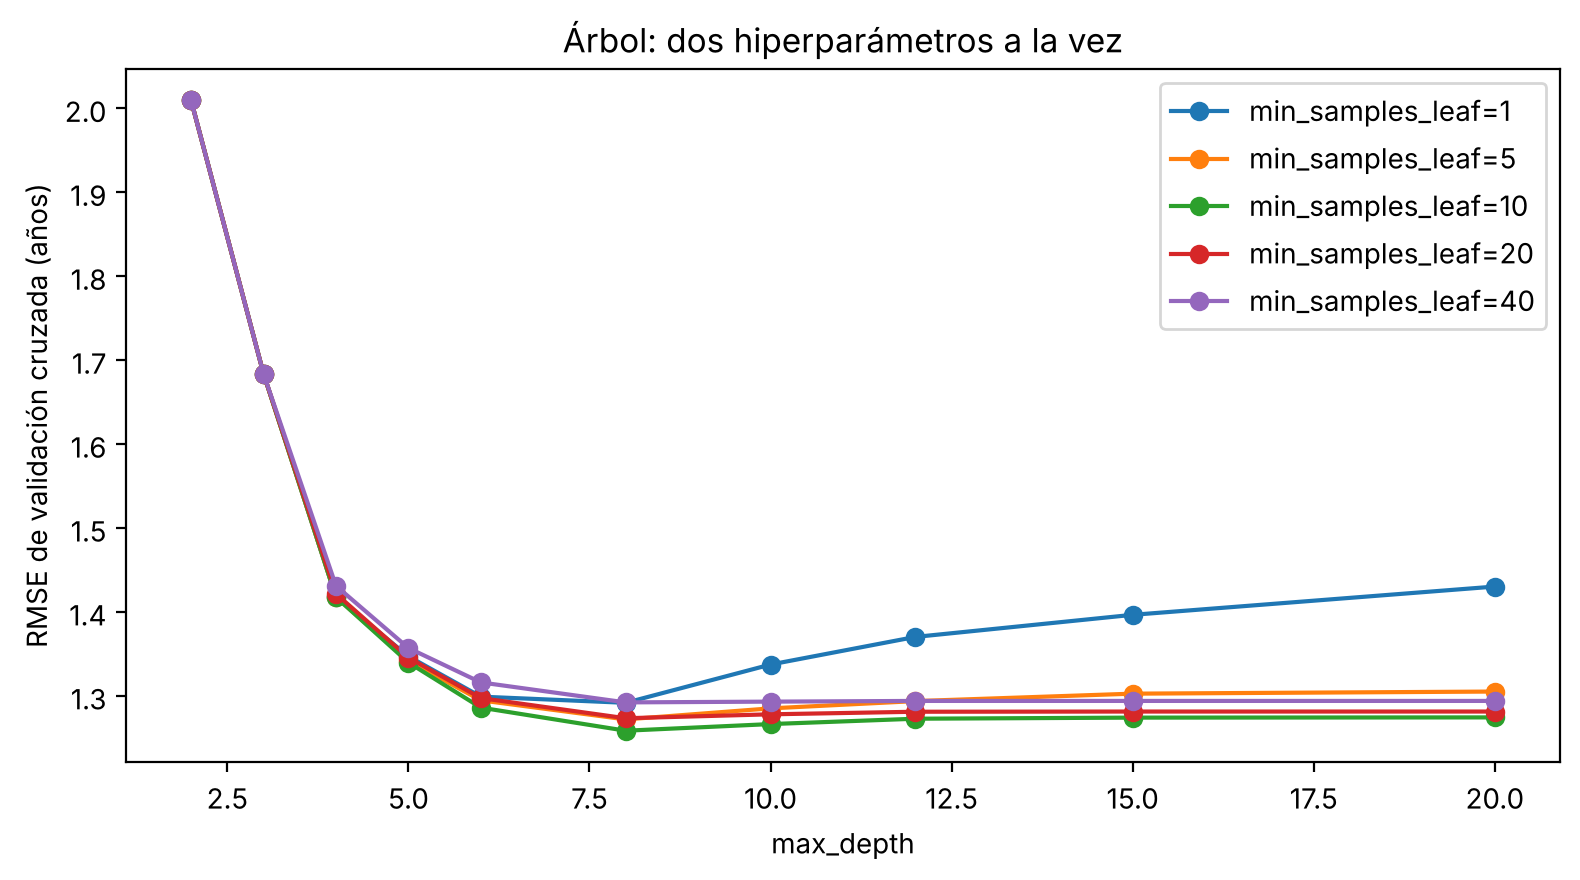

In [4]:
r = pd.DataFrame(b_arbol.cv_results_)
r["max_depth"] = r["param_modelo__max_depth"].astype(int)
r["min_samples_leaf"] = r["param_modelo__min_samples_leaf"].astype(int)

fig, ax = plt.subplots(figsize=(8, 4.5))
for hoja, grupo in r.groupby("min_samples_leaf"):
    ax.plot(grupo["max_depth"], -grupo["mean_test_score"], "o-", label=f"min_samples_leaf={hoja}")
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE de validación cruzada (años)")
ax.set_title("Árbol: dos hiperparámetros a la vez")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTADOS / "04_arbol_grid.png", dpi=150)
plt.show()

## kNN (grid search)

In [5]:
grilla_knn = {"n_neighbors": [3, 5, 7, 10, 15, 20, 30, 50, 75], "weights": ["uniform", "distance"], "p": [1, 2]}
b_knn, t_knn = busqueda_grid(KNN, grilla_knn, X_dev, y_dev)
print(f"{len(b_knn.cv_results_['params'])} combinaciones en {t_knn:.0f} s")
resultados_cv(b_knn, k=5)

36 combinaciones en 24 s


,hiperparámetros,rmse_cv,desv_cv,ranking
0,"{'n_neighbors': 20, 'p': 2, 'weights': 'uniform'}",1.394,0.030,1
1,"{'n_neighbors': 30, 'p': 2, 'weights': 'distance'}",1.396,0.023,2
2,"{'n_neighbors': 20, 'p': 2, 'weights': 'distance'}",1.397,0.019,3
3,"{'n_neighbors': 15, 'p': 2, 'weights': 'uniform'}",1.397,0.027,4
4,"{'n_neighbors': 10, 'p': 2, 'weights': 'uniform'}",1.397,0.024,5


## Random Forest: grid search contra random search

Con el **mismo presupuesto** (8 combinaciones, cada una evaluada con 5 particiones). El grid recorre una malla
pequeña; el random sortea de un espacio más amplio, que incluye valores intermedios que la malla no tiene.

In [6]:
FIJOS_BOSQUE = {"n_estimators": 50}   # 50 árboles en las búsquedas para que tarden menos
grilla_bosque = {"max_depth": [8, None], "min_samples_leaf": [1, 5], "max_features": ["sqrt", 1.0]}
b_bosque_grid, t_bosque_grid = busqueda_grid(BOSQUE, grilla_bosque, X_dev, y_dev, **FIJOS_BOSQUE)
print(f"grid: {len(b_bosque_grid.cv_results_['params'])} combinaciones en {t_bosque_grid:.0f} s")
resultados_cv(b_bosque_grid, k=5)

grid: 8 combinaciones en 37 s


,hiperparámetros,rmse_cv,desv_cv,ranking
0,"{'max_depth': 8, 'max_features': 1.0, 'min_samples_leaf': 5}",1.252,0.016,1
1,"{'max_depth': 8, 'max_features': 1.0, 'min_samples_leaf': 1}",1.262,0.018,2
2,"{'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 5}",1.269,0.016,3
3,"{'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1}",1.337,0.016,4
4,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}",1.363,0.028,5


In [7]:
espacio_bosque = {
    "max_depth": [3, 5, 8, 12, 16, None],
    "min_samples_leaf": randint(1, 21),
    "max_features": [0.3, 0.5, 0.7, 1.0, "sqrt"],
}
b_bosque_rand, t_bosque_rand = busqueda_random(BOSQUE, espacio_bosque, X_dev, y_dev, n_iter=8, **FIJOS_BOSQUE)
print(f"random: {len(b_bosque_rand.cv_results_['params'])} combinaciones en {t_bosque_rand:.0f} s")
resultados_cv(b_bosque_rand, k=5)

random: 8 combinaciones en 20 s


,hiperparámetros,rmse_cv,desv_cv,ranking
0,"{'max_depth': 16, 'max_features': 0.5, 'min_samples_leaf': 17}",1.288,0.033,1
1,"{'max_depth': 5, 'max_features': 0.7, 'min_samples_leaf': 14}",1.305,0.019,2
2,"{'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1}",1.337,0.016,3
3,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3}",1.398,0.045,4
4,"{'max_depth': 5, 'max_features': 0.3, 'min_samples_leaf': 8}",1.613,0.068,5


## Resumen de las búsquedas

In [8]:
busquedas = {
    "Árbol de decisión": ("grid", b_arbol, t_arbol),
    "kNN": ("grid", b_knn, t_knn),
    "Random Forest (grid)": ("grid", b_bosque_grid, t_bosque_grid),
    "Random Forest (random)": ("random", b_bosque_rand, t_bosque_rand),
}
resumen_busquedas = pd.DataFrame([
    {
        "modelo": nombre,
        "método": metodo,
        "combinaciones": len(b.cv_results_["params"]),
        "segundos": seg,
        "mejor RMSE (validación cruzada)": -b.best_score_,
        "mejores hiperparámetros": mejores_hiperparametros(b),
    }
    for nombre, (metodo, b, seg) in busquedas.items()
])
resumen_busquedas

,modelo,método,combinaciones,segundos,mejor RMSE (validación cruzada),mejores hiperparámetros
0,Árbol de decisión,grid,50,8.089,1.258,"{'max_depth': 8, 'min_samples_leaf': 10}"
1,kNN,grid,36,24.490,1.394,"{'n_neighbors': 20, 'p': 2, 'weights': 'uniform'}"
2,Random Forest (grid),grid,8,37.402,1.252,"{'max_depth': 8, 'max_features': 1.0, 'min_samples_leaf': 5}"
3,Random Forest (random),random,8,20.497,1.288,"{'max_depth': 16, 'max_features': 0.5, 'min_samples_leaf': 17}"


In [9]:
# Se guardan los mejores hiperparámetros para el cuaderno 05.
def a_json(o):
    return o.item() if hasattr(o, "item") else str(o)

guardado = {
    nombre: {
        "params": {**(FIJOS_BOSQUE if "Forest" in nombre else {}), **mejores_hiperparametros(b)},
        "rmse_cv": float(-b.best_score_),
    }
    for nombre, (_, b, _) in busquedas.items()
}
with open(RESULTADOS / "mejores_hiperparametros.json", "w") as f:
    json.dump(guardado, f, indent=2, default=a_json)
print("guardado en resultados/mejores_hiperparametros.json")

guardado en resultados/mejores_hiperparametros.json


### Lectura de resultados
- **Árbol** (grid, 50 combinaciones): `max_depth = 8` y `min_samples_leaf = 10`, con RMSE de validación cruzada 1,258.
- **kNN** (grid, 36 combinaciones): `k = 20`, distancia euclidiana (`p = 2`) y pesos uniformes, con 1,394.
- **Random Forest**, mismo presupuesto de 8 combinaciones: el grid encontró 1,252 (`max_depth = 8`, `max_features = 1.0`, `min_samples_leaf = 5`) y el random 1,288. Aquí ganó el grid, pero con solo 8 sorteos el random depende de la suerte, así que no es una conclusión general sobre los dos métodos.
- Los ganadores usan restricciones de complejidad moderadas (profundidad 8, hojas con varias personas), igual que sugerían las curvas del cuaderno 03.

### Mi análisis
*(Escríbelo con tus palabras. Preguntas para guiarte: ¿qué combinación de hiperparámetros ganó en cada modelo y qué significa en términos de complejidad? ¿El random search encontró algo tan bueno como el grid con el mismo número de combinaciones? ¿Cuándo conviene uno y cuándo el otro? ¿Por qué se usa validación cruzada y no el conjunto de prueba para elegir?)*